# Tiered fraud classifier (per transaction)

This notebook replaces fraud-probability imputation with a classifier. Each transaction gets a probability of belonging to each of these tiers:

| Tier | Supplied consumer fraud score | Meaning |
|---|---|---|
| 0 | < 30 | scored, low |
| 1 | 30–50 | watch |
| 2 | 50–70 | flagged |
| 3 | ≥ 70 | high |

**Linking scores to transactions.** `consumer_fraud_probability` is recorded per `(user_id, order_date)`, and `order_datetime` has no time of day. So a score can be tied to one exact transaction only when the user made a single transaction that day. Every scored user-day matches at least one transaction, but only about 27% match exactly one. The rest are shared by 2 or more transactions, and nothing in the data says which of them the score refers to.

The classifier is therefore trained per transaction, with each transaction inheriting its day's score. It uses transaction-level features only, so different transactions on the same day can get different predictions. It is evaluated on the single-transaction days, where the transaction-level label is exact, and at the user-day level.

**Scope.** Only scored user-days are used for training. Tier 0 means "scored, but below 30", not "not fraudulent". Scores only exist for a pre-screened subset (the minimum score is about 8%), so predictions on never-scored transactions are outside the training data and should be treated as a ranking for review, not a calibrated probability.

## 1. Setup

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

# Works when launched from the repository, project2, or notebooks directory.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if p.name == "project2"), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd() / "project2"
PROCESSED_PATH = PROJECT_ROOT / "data" / "tables" / "processed"
if not PROCESSED_PATH.is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to your project2 directory.")
RANDOM_STATE = 42
CUTOFFS = [30, 50, 70]
TIER_NAMES = {0: "<30", 1: "30-50", 2: "50-70", 3: ">=70"}
spark = SparkSession.builder.config("spark.driver.memory", "6g").getOrCreate()

## 2. Transaction-level behavioural features

These are computed over **all** ~14M transactions and do not use the fraud scores. The fraud score tracks transaction size relative to what is normal for that user and merchant, so the key features are ratios to the user's and the merchant's median transaction.

Aggregates use the whole sample period, including transactions after the one being scored. That's fine for describing the data, but a live system would need them computed from past transactions only.

In [15]:
trans = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    # Drop the attached scores: they are the label, not features.
    .drop("_source_order", "consumer_fraud_probability", "merchant_fraud_probability")
    .withColumn("order_date", F.to_date("order_datetime"))
)

user_w = Window.partitionBy("user_id")
merchant_w = Window.partitionBy("merchant_abn")
user_merchant_w = Window.partitionBy("user_id", "merchant_abn")
day_w = Window.partitionBy("user_id", "order_date")

trans_features = (
    trans
    .withColumn("user_txn_count", F.count("*").over(user_w))
    .withColumn("user_median_value", F.percentile_approx("dollar_value", 0.5).over(user_w))
    .withColumn("merchant_txn_count", F.count("*").over(merchant_w))
    .withColumn("merchant_median_value", F.percentile_approx("dollar_value", 0.5).over(merchant_w))
    .withColumn("user_merchant_txn_count", F.count("*").over(user_merchant_w))
    # Only used to measure the link between scores and transactions, not as a feature.
    .withColumn("day_txn_count", F.count("*").over(day_w))
)

## 3. Attach scores to transactions

An inner join on `(user_id, order_date)` keeps every transaction on a scored user-day. Each one inherits that day's score.

In [16]:
scores = (
    spark.read.parquet(str(PROCESSED_PATH / "consumer_fraud_probability"))
    .where(F.col("fraud_probability").isNotNull())
    .withColumn("order_date", F.to_date("order_datetime"))
    .drop("order_datetime")
)
merchants = spark.read.parquet(str(PROCESSED_PATH / "merchants_clean")).select(
    "merchant_abn", "revenue_code", "take_rate")
consumers_sa2 = (
    spark.read.parquet(
        str(PROCESSED_PATH / "consumers_sa2")
    )
    .drop(
        "consumer_id",
        "postcode",
        "sa2_matched",
        "sa2_code",
        "sa2_name",
        "sa2_state_name",
        "sa2_share",
        "n_sa2s",
    )
)

labelled = (
    scores.join(trans_features, ["user_id", "order_date"], "inner")
    .join(merchants, "merchant_abn", "left")
    .join(consumers_sa2, "user_id", "left")
).toPandas()

print(f"{scores.count():,} scored user-days -> {len(labelled):,} transactions")

34,765 scored user-days -> 80,348 transactions


In [17]:
p = labelled["fraud_probability"]
labelled["tier"] = np.select([p >= 70, p >= 50, p >= 30], [3, 2, 1], 0)
labelled["order_date"] = pd.to_datetime(labelled["order_date"])
labelled["day_key"] = (labelled["user_id"].astype(str) + "_"
                       + labelled["order_date"].dt.strftime("%Y%m%d"))

days = labelled.drop_duplicates("day_key")
linkage = pd.crosstab(days["tier"],
                      np.where(days["day_txn_count"] == 1, "exact (1 txn)", "shared (2+ txns)"),
                      margins=True).rename(index=TIER_NAMES)
linkage

col_0,exact (1 txn),shared (2+ txns),All
tier,,,
<30,8680,23901,32581
30-50,483,1105,1588
50-70,154,333,487
>=70,40,69,109
All,9357,25408,34765


## 4. Model features

In [18]:
df = labelled
df["log_value"] = np.log1p(df["dollar_value"])
df["value_vs_user_median"] = df["dollar_value"] / df["user_median_value"]
df["value_vs_merchant_median"] = df["dollar_value"] / df["merchant_median_value"]
df["day_of_week"] = df["order_date"].dt.dayofweek
df["month"] = df["order_date"].dt.month
CAT_COLS = ["revenue_code", "state", "gender"]
for col in CAT_COLS:
    df[col] = df[col].fillna("Missing").astype("category")

ABS_COLS = [
    c for c in df.columns
    if c.startswith(("abs_", "seifa_"))
]
FEATURES = [
    "log_value",
    "value_vs_user_median",
    "value_vs_merchant_median",
    "user_txn_count",
    "user_median_value",
    "merchant_txn_count",
    "merchant_median_value",
    "user_merchant_txn_count",
    "take_rate",
    *CAT_COLS,
    "day_of_week",
    "month",
    *ABS_COLS,
]

## 5. Grouped, stratified split

The split is by `user_id`, so no consumer appears in both train and test. It is stratified by tier, so the test set gets its share of the rare ≥70 days.

In [19]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(df, df["tier"], groups=df["user_id"]))
train, test = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
assert not set(train["user_id"]) & set(test["user_id"])

pd.DataFrame({
    "train days": train.drop_duplicates("day_key")["tier"].value_counts(),
    "test days": test.drop_duplicates("day_key")["tier"].value_counts(),
}).rename(index=TIER_NAMES).sort_index()

,train days,test days
tier,,
30-50,1299,289
50-70,384,103
<30,26084,6497
>=70,87,22


## 6. Cumulative models: P(score ≥ 30), P(≥ 50), P(≥ 70)

In [20]:
# Every transaction on a scored day inherits that day's score, so labels on
# shared days are noisy. Weighting by 1/day_txn_count makes each user-day
# contribute a total weight of 1, however many transactions it had. This beat
# training on single-transaction days only, especially at the user-day level.
train_weight = 1.0 / train["day_txn_count"]

models = {}
for k in CUTOFFS:
    models[k] = XGBClassifier(
        n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8,
        colsample_bytree=0.8, min_child_weight=5, enable_categorical=True,
        tree_method="hist", random_state=RANDOM_STATE)
    models[k].fit(train[FEATURES], (train["fraud_probability"] >= k).astype(int),
                  sample_weight=train_weight)

In [21]:
def predict_cumulative(frame):
    probs = pd.DataFrame({k: models[k].predict_proba(frame[FEATURES])[:, 1] for k in CUTOFFS},
                         index=frame.index)
    # Separate models can cross; enforce P(>=70) <= P(>=50) <= P(>=30).
    probs[50] = np.minimum(probs[50], probs[30])
    probs[70] = np.minimum(probs[70], probs[50])
    return probs

def tier_probabilities(cum):
    return pd.DataFrame({"p_tier_0": 1 - cum[30], "p_tier_1": cum[30] - cum[50],
                         "p_tier_2": cum[50] - cum[70], "p_tier_3": cum[70]})

cum = predict_cumulative(test)

for k in CUTOFFS:
    test[f"p_ge_{k}"] = cum[k]
test = test.join(tier_probabilities(cum))

## 7. Evaluation

Each cutoff is scored on two sets:

- **Single-transaction days**: the transaction-level label is exact.
- **All user-days**: a day's prediction is its highest-scoring transaction.

The PR-AUC of a random ranking equals the prevalence, which is the baseline to compare against.

In [22]:
day_pred = test.groupby("day_key").agg(
    fraud_probability=("fraud_probability", "first"),
    **{f"p_ge_{k}": (f"p_ge_{k}", "max") for k in CUTOFFS})
single = test[test["day_txn_count"] == 1]

rows = []
for k in CUTOFFS:
    for name, frame in [("single-txn days", single), ("all user-days (max)", day_pred)]:
        y = (frame["fraud_probability"] >= k).astype(int)
        rows.append({"cutoff": f">={k}", "evaluated on": name, "n": len(frame),
                     "positives": int(y.sum()), "prevalence": y.mean(),
                     "PR-AUC": average_precision_score(y, frame[f"p_ge_{k}"]),
                     "ROC-AUC": roc_auc_score(y, frame[f"p_ge_{k}"]),
                     "mean predicted": frame[f"p_ge_{k}"].mean()})
pd.DataFrame(rows).round(3)

,cutoff,evaluated on,n,positives,prevalence,PR-AUC,ROC-AUC,mean predicted
0,>=30,single-txn days,1853,135,0.073,0.969,0.997,0.074
1,>=30,all user-days (max),6911,414,0.060,0.941,0.987,0.101
2,>=50,single-txn days,1853,44,0.024,0.922,0.998,0.020
3,>=50,all user-days (max),6911,125,0.018,0.920,0.995,0.027
4,>=70,single-txn days,1853,10,0.005,0.767,0.998,0.003
5,>=70,all user-days (max),6911,22,0.003,0.604,0.989,0.005


The tier confusion matrix uses single-transaction days. A transaction is assigned the highest tier whose cumulative probability is ≥ 0.5. That 0.5 is a default operating point, not a tuned one.

In [23]:
def assign_tier(frame, threshold=0.5):
    return np.select([frame["p_ge_70"] >= threshold, frame["p_ge_50"] >= threshold,
                      frame["p_ge_30"] >= threshold], [3, 2, 1], 0)

cm = confusion_matrix(single["tier"], assign_tier(single), labels=[0, 1, 2, 3])
pd.DataFrame(cm, index=[f"actual {TIER_NAMES[t]}" for t in range(4)],
             columns=[f"pred {TIER_NAMES[t]}" for t in range(4)])

,pred <30,pred 30-50,pred 50-70,pred >=70
actual <30,1703,15,0,0
actual 30-50,9,79,3,0
actual 50-70,0,11,22,1
actual >=70,0,0,6,4


## 8. Which transaction on a shared day?

For flagged days with 2 or more transactions, this compares the highest-scoring transaction in the day with the second highest. A large gap means the model singles out one transaction as the likely source of the day's score.

In [24]:
multi = test[(test["day_txn_count"] > 1) & (test["tier"] >= 1)]
ranked = multi.sort_values("p_ge_30", ascending=False).groupby("day_key")["p_ge_30"]
attribution = pd.DataFrame({"top": ranked.nth(0).values, "second": ranked.nth(1).values})
print(f"{len(attribution):,} flagged test days with 2+ transactions")
print(attribution.describe().round(3))
print("Share with top >= 0.5 and second < 0.2:",
      round(((attribution["top"] >= 0.5) & (attribution["second"] < 0.2)).mean(), 3))

279 flagged test days with 2+ transactions
           top   second
count  279.000  279.000
mean     0.812    0.060
std      0.268    0.017
min      0.044    0.002
25%      0.794    0.050
50%      0.947    0.058
75%      0.980    0.070
max      0.995    0.137
Share with top >= 0.5 and second < 0.2: 0.853


## 9. Feature importance (≥ 50 model, gain)

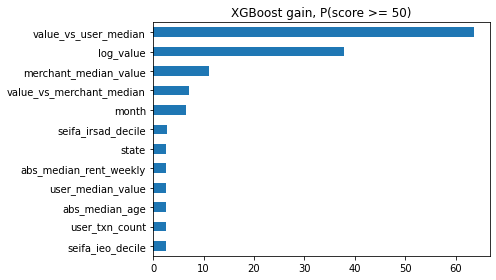

In [25]:
gain = pd.Series(models[50].get_booster().get_score(importance_type="gain")).sort_values()
gain.tail(12).plot.barh(figsize=(7, 4), title="XGBoost gain, P(score >= 50)")
plt.tight_layout()
plt.show()

In [26]:
# ------------------------------------------------------------
# Save trained consumer fraud models and held-out test data
# ------------------------------------------------------------

MODEL_DIR = PROJECT_ROOT / "data" / "tables" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save each XGBoost cutoff model.
for cutoff, model in models.items():

    model_path = (
        MODEL_DIR
        / f"consumer_fraud_ge{cutoff}.json"
    )

    model.save_model(model_path)

    print(
        f"Saved model: {model_path.name}"
    )


# Save the held-out test set used for final evaluation/plots.
consumer_test_path = (
    MODEL_DIR
    / "consumer_fraud_test.parquet"
)

test.to_parquet(
    consumer_test_path,
    index=False,
)

print(
    f"Saved test data: {consumer_test_path.name}"
)

print("\nFiles written to:")
print(MODEL_DIR)

Saved model: consumer_fraud_ge30.json
Saved model: consumer_fraud_ge50.json
Saved model: consumer_fraud_ge70.json
Saved test data: consumer_fraud_test.parquet

Files written to:
/Users/matthewwihartanto/Documents/University /Year 3/Sem 1/Applied DS/GitHub/project2/data/tables/models


## Interpretation and limitations

- **What the score tracks.** On single-transaction days, the supplied score has a Spearman correlation of about 0.91 with log transaction value. The median transaction overall is about $62, but the median largest transaction on a scored day is about $3,300. The classifier is mostly learning "large relative to this user's and this merchant's usual transaction".
- **Linking to transactions.** The link is exact only on single-transaction days (about 27% of scored days). On shared days, the model's per-transaction scores point to a likely transaction, but that's the model's inference, not something recorded in the data.
- **The ≥70 tier is thin.** There are 109 user-days in total and about 20 in the test fold, so its metrics are noisy. Use cross-validation or several seeds before quoting them.
- **Scope.** Tier probabilities are only meaningful for transactions like the scored ones. On never-scored transactions, use them as a ranking for review, not as a calibrated fraud probability.
- **Operating points.** The 0.5 cutoff in the confusion matrix is a default. Pick flag thresholds from the precision each tier needs.
- Nothing is exported. Merchant-level flag features are a separate next step.